[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/santiagovelcasallas/incorporacion-restricciones-aprendizaje-automatico/blob/main/notebooks/ccd_radiologia_maira2.ipynb)

**Exposición:** Incorporación de restricciones a modelos de aprendizaje automático · Runtime recomendado: **GPU A100** (L4 también sirve; T4 no alcanza para MAIRA-2 de 7B).

# Restricción post-entrenamiento sobre los logits de un Transformer radiológico
**CCD — Clinical Contrastive Decoding** (Zhang, Meng, Lever & Ho, **ACL 2026**). Código oficial: github.com/X-iZhang/CCD

- **Modelo:** MAIRA-2 (Microsoft), Transformer multimodal que escribe el informe de una radiografía de tórax. **Pesos congelados.**
- **Datos:** IU X-Ray (Indiana University, acceso libre). Comparamos con el informe real del radiólogo.
- **La restricción:** en cada palabra que el Transformer va a escribir, se corrigen sus **logits** con la evidencia de un modelo experto (DenseNet CheXpert) que mira la misma radiografía:
  `logits_finales = (1-β)·logits_modelo + β·(logits_modelo + sesgo_experto)`,   con `sesgo = log(p/(1-p))` acotado a ±log γ
  → si el experto ve derrame pleural, la palabra "effusion" se vuelve más probable; si no lo ve, menos probable.
- **Métrica:** CheXbert (Smit et al., EMNLP 2020) lee ambos informes y marca 14 hallazgos → **precisión, recall y F1 clínicos**.

*Demostración académica, no es una herramienta clínica.*

**Runtime → Cambiar tipo de entorno → GPU A100 (o L4).**

### Cómo está organizado
| Celdas | Qué hacen | ¿GPU? |
|---|---|---|
| **1 → 5** | Instalar, elegir estudios, cargar MAIRA-2, generar informes con y sin restricción, evaluar con CheXbert | Sí (A100, ~10 min) |
| **6 → 7** | Vista rápida (primera versión de las gráficas) | No |
| **A → B** | Guardar / cargar los resultados (B los lee de este repositorio) | No |
| **C → H** | Métricas con IC 95 %, bootstrap, matrices de confusión, ROC, balance por paciente y galería | No |

**Para revisar: Entorno de ejecución → Ejecutar todo.** Con `GENERAR = False` (celda 1, valor por defecto) el notebook corre completo en segundos en cualquier Colab, incluso sin GPU: omite la generación y dibuja todo con los resultados guardados.

Para volver a generar los informes: GPU A100 y `GENERAR = True`.

## 1. Interruptor e instalación
`GENERAR = False` (por defecto): no instala nada y usa los resultados guardados en el repositorio. `GENERAR = True`: instala la librería oficial de CCD (y Libra, su base), fijadas a las versiones usadas, y regenera todo en una GPU A100.

In [ ]:
# 1) Interruptor e instalación
#    GENERAR = False → no se instala ni se genera nada: las celdas B → H cargan los resultados guardados en este
#                      repositorio. Funciona con "Ejecutar todo" en cualquier Colab, incluso sin GPU (recomendado para revisar).
#    GENERAR = True  → se vuelven a generar los informes: requiere GPU A100 (~4 min de instalación + ~10 min de generación).
#    Libra y CCD se instalan con --no-deps porque Libra fija torch==2.4.0, que no existe para Python 3.13; se usa el torch
#    de Colab. Versiones fijadas: Libra v1.0.3 y CCD commit 8cefd7f (las usadas en la corrida).
GENERAR = False

if GENERAR:
    !nvidia-smi --query-gpu=name,memory.total --format=csv
    !pip -q install --no-deps "git+https://github.com/X-iZhang/Libra.git@v1.0.3" "git+https://github.com/X-iZhang/CCD.git@8cefd7fcd2f222cfb102e1e33b3918bf98ad6d4e" f1chexbert appdirs
    !pip -q install "transformers==4.51.3" "tokenizers==0.21.1" "accelerate==1.6.0" shortuuid einops-exts torchxrayvision scikit-image peft sentencepiece pydicom markdown2
    !pip -q install -U protobuf   # la TensorFlow de Colab necesita protobuf reciente (además desactivamos TF en la celda 2)
    print("Instalación lista. Continúa con la celda 2.")
else:
    print("GENERAR = False: se omiten la instalación y la generación (celdas 1–7 y A).")
    print("Los resultados guardados se cargan en la celda B y las celdas C → H dibujan todo.")

## 2. Configuración y datos
IU X-Ray (Indiana University, acceso libre), sección *findings*, radiografías frontales. Parámetros de CCD: los del paper (α = β = 0,5, γ = 10).

In [1]:
# 2) Configuración y datos
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    import os; os.environ["USE_TF"] = "0"   # que transformers no cargue TensorFlow (choca con protobuf en Colab)
    import transformers
    if transformers.__version__ != "4.51.3":
        raise RuntimeError(f"transformers {transformers.__version__} ya estaba cargado: ve a Entorno de ejecución → "
                           "Reiniciar sesión y vuelve a ejecutar desde la celda 1 (con GENERAR = True).")
    import io, json, time, random
    import numpy as np, pandas as pd, torch
    from PIL import Image
    from huggingface_hub import hf_hub_download

    MODEL = "X-iZhang/libra-maira-2"     # alternativa más liviana: "X-iZhang/libra-v1.0-3b"
    N = 20                               # muestra aleatoria inicial (la celda 2b la reemplaza por 30 estudios CON hallazgos)
    OUT = "/content/ccd_resultados.json" # se guarda tras cada caso: si Colab se cae, se retoma
    ALPHA, BETA, GAMMA = 0.5, 0.5, 10    # parámetros por defecto del paper
    print(torch.cuda.get_device_name(0))

    # IU X-Ray: primer fragmento (237 estudios) del split de prueba preparado por los autores de CCD
    p = hf_hub_download("X-iZhang/IU-Xray-RRG", "findings_section/test-00000-of-00014.parquet", repo_type="dataset")
    df = pd.read_parquet(p)
    # descartamos informes vacíos o muy cortos
    df = df[df["findings_section"].str.len() > 30].reset_index(drop=True)
    sel = df.sample(n=N, random_state=0)
    img_of = lambda r: Image.open(io.BytesIO(r["main_image"]["bytes"])).convert("RGB")
    print(len(df), "estudios disponibles en este fragmento ·", N, "seleccionados")
    print("Prompt:", sel.iloc[0]["default_prompt"])

NVIDIA A100-SXM4-40GB


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


237 estudios disponibles en este fragmento · 20 seleccionados
Prompt: Provide a detailed description of the findings in the radiology image.


## 2b. Elegir estudios con hallazgos
En una muestra aleatoria casi todos los estudios son normales y ambas versiones dicen "normal". Para medir el efecto de la restricción se toman **30 estudios con al menos uno de los 5 hallazgos principales** según el informe del radiólogo (semilla fija).

In [10]:
# 2b) Seleccionar estudios CON hallazgos (CheXbert sobre el informe del radiólogo)
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    import os, shutil, functools, torch
    from huggingface_hub import hf_hub_download
    from f1chexbert import F1CheXbert
    # CheXbert (Smit et al., 2020): lee un informe y marca 14 hallazgos. f1chexbert espera su checkpoint en
    # ~/.cache/chexbert, y torch ≥ 2.6 exige weights_only=False para cargar este archivo (es de Stanford AIMI).
    os.makedirs("/root/.cache/chexbert", exist_ok=True)
    if not os.path.exists("/root/.cache/chexbert/chexbert.pth"):
        shutil.copy(hf_hub_download("StanfordAIMI/RRG_scorers", "chexbert.pth"), "/root/.cache/chexbert/chexbert.pth")
    _tl = torch.load; torch.load = functools.partial(_tl, weights_only=False)
    cx = F1CheXbert(); torch.load = _tl

    # Etiquetamos el informe del RADIÓLOGO y nos quedamos con estudios que tienen ≥ 1 de los 5 hallazgos principales:
    # CCD solo puede marcar diferencia donde hay algo que detectar (en una muestra al azar casi todo era normal).
    lab = np.array([cx.get_label(t) for t in df["findings_section"]])
    idx5 = list(cx.target_names_5_index)
    abn = np.where(lab[:, idx5].sum(1) > 0)[0]                 # tienen ≥1 de los 5 hallazgos principales
    print(f"{len(abn)} de {len(df)} estudios tienen al menos un hallazgo principal")
    sel = df.iloc[abn].sample(n=min(30, len(abn)), random_state=0)
    OUT = "/content/ccd_hallazgos.json"                        # archivo nuevo, no mezcla con el anterior

40 de 237 estudios tienen al menos un hallazgo principal


## 3. Cargar el Transformer y el experto
MAIRA-2 (7 B parámetros) en la versión adaptada por los autores de CCD. El experto (DenseNet-121 CheXpert de `torchxrayvision`) se carga automáticamente la primera vez que se usa.

In [11]:
# 3) Cargar el Transformer (una sola vez) y el experto
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    import time
    from ccd import run_eval, ccd_eval
    from ccd.run_ccd import get_libra_model
    from ccd.ccd_utils import predict_chexpert_labels

    if 'MODEL' not in globals():
        MODEL = "X-iZhang/libra-maira-2"
        print("⚠️ 'MODEL' no estaba definido. Usando valor por defecto:", MODEL)

    # Descarga MAIRA-2 (~15 GB) y lo deja en memoria; las celdas siguientes lo reutilizan.
    t = time.time(); LIBRA = get_libra_model(MODEL); print(f"modelo cargado en {time.time()-t:.0f}s")

modelo cargado en 0s


## 4. Generar informes con y sin la restricción
Para cada radiografía se generan **dos informes con el mismo modelo y los mismos pesos**:
- `run_eval`: decodificación greedy normal.
- `ccd_eval`: en cada palabra, los logits se corrigen con el experto: `ℓ_final = ℓ_guía + β·b`, con `b = clip(log p/(1−p), ±log γ)` sobre las palabras de cada hallazgo, y `ℓ_guía` la mezcla (α) del modelo con y sin la nota clínica del experto.

Tiempo en A100: ~1,4 s por informe sin restricción y ~11,5 s con CCD (dos pasadas del modelo por palabra).

In [12]:
# 4) Generar informes: SIN restricción (decodificación normal, greedy) vs CON restricción (CCD)
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    import os, json, time

    if 'OUT' not in globals() or 'LIBRA' not in globals():
        raise RuntimeError("⚠️ Faltan variables. Por favor, ejecuta primero la Celda 2 (Configuración) y la Celda 3 (Cargar modelo).")

    # run_eval = decodificación normal (greedy): el Transformer tal cual.
    # ccd_eval = la misma decodificación, pero en CADA palabra se corrigen los logits con el experto (α, β, γ).
    # Los pesos de MAIRA-2 son idénticos en ambos casos. Se guarda tras cada estudio para poder retomar si Colab se cae.
    first = lambda o: o[0] if isinstance(o, (list, tuple)) else o
    res = json.load(open(OUT)) if os.path.exists(OUT) else {}
    for k, (i, r) in enumerate(sel.iterrows()):
        key = str(i)
        if key in res: continue
        img, q = img_of(r), r["default_prompt"]
        t0 = time.time()
        base = first(run_eval(model_path=MODEL, image=img, question=q, max_new_tokens=128, libra_model=LIBRA))
        t1 = time.time()
        ccd = ccd_eval(model_path=MODEL, image=img, question=q, max_new_tokens=128, libra_model=LIBRA,
                       alpha=ALPHA, beta=BETA, gamma=GAMMA, expert_model="DenseNet")
        t2 = time.time()
        res[key] = dict(ref=r["findings_section"], base=base, ccd=ccd, expert=predict_chexpert_labels(img),
                        t_base=t1 - t0, t_ccd=t2 - t1)
        json.dump(res, open(OUT, "w"))
        print(f"{k+1}/{N}  base {t1-t0:.1f}s · CCD {t2-t1:.1f}s")
    print("listo:", len(res), "informes")

1/20  base 1.7s · CCD 10.8s
2/20  base 1.4s · CCD 13.3s
3/20  base 2.2s · CCD 14.6s
4/20  base 1.4s · CCD 12.0s
5/20  base 1.4s · CCD 10.2s
6/20  base 1.4s · CCD 10.3s
7/20  base 1.4s · CCD 14.8s
8/20  base 0.5s · CCD 11.6s
9/20  base 0.6s · CCD 7.0s
10/20  base 1.4s · CCD 17.3s
11/20  base 1.4s · CCD 11.5s
12/20  base 1.4s · CCD 10.3s
13/20  base 1.4s · CCD 13.4s
14/20  base 1.4s · CCD 10.3s
15/20  base 2.2s · CCD 9.4s
16/20  base 1.4s · CCD 12.8s
17/20  base 1.4s · CCD 11.5s
18/20  base 2.0s · CCD 13.6s
19/20  base 1.4s · CCD 13.4s
20/20  base 1.5s · CCD 12.8s
21/20  base 2.0s · CCD 13.9s
22/20  base 0.5s · CCD 7.1s
23/20  base 1.0s · CCD 10.9s
24/20  base 2.7s · CCD 13.7s
25/20  base 2.0s · CCD 13.0s
26/20  base 1.4s · CCD 10.3s
27/20  base 1.4s · CCD 10.3s
28/20  base 1.4s · CCD 11.7s
29/20  base 0.5s · CCD 10.5s
30/20  base 1.4s · CCD 12.8s
listo: 30 informes


## 5. Evaluación clínica con CheXbert
CheXbert lee los tres textos de cada estudio (radiólogo, original y con CCD) y marca 14 hallazgos. Comparando las etiquetas del modelo con las del radiólogo se calculan **precisión, recall y F1**, en micro-promedio (todos los pares hallazgo-estudio juntos) y macro-promedio (promedio por hallazgo).

In [13]:
# 5) Evaluación clínica con CheXbert: precisión, recall y F1 (+ IC 95 % bootstrap pareado)
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    import os, shutil, functools, torch
    from huggingface_hub import hf_hub_download
    from f1chexbert import F1CheXbert
    from sklearn.metrics import precision_recall_fscore_support
    os.makedirs("/root/.cache/chexbert", exist_ok=True)
    if not os.path.exists("/root/.cache/chexbert/chexbert.pth"):
        shutil.copy(hf_hub_download("StanfordAIMI/RRG_scorers", "chexbert.pth"), "/root/.cache/chexbert/chexbert.pth")
    _tl = torch.load; torch.load = functools.partial(_tl, weights_only=False)
    cx = F1CheXbert()
    torch.load = _tl
    # Etiquetas CheXbert de los tres textos de cada estudio: ref (radiólogo), base (original), ccd (con restricción)
    NAMES = cx.target_names; IDX5 = list(cx.target_names_5_index)
    keys = list(res)
    L = {s: np.array([cx.get_label(res[k][s]) for k in keys]) for s in ["ref", "base", "ccd"]}


    def prf(yt, yp, avg):
        p, r, f, _ = precision_recall_fscore_support(yt, yp, average=avg, zero_division=0); return np.array([p, r, f])


    # Métrica (micro o macro) de cada modelo + IC 95 % bootstrap pareado de la diferencia CCD − original
    def table(cols, avg):
        yt = L["ref"][:, cols]; out = {}
        for s in ["base", "ccd"]: out[s] = prf(yt, L[s][:, cols], avg)
        rng = np.random.default_rng(0); D = []
        for _ in range(2000):
            j = rng.integers(0, len(keys), len(keys))
            D.append(prf(yt[j], L["ccd"][j][:, cols], avg) - prf(yt[j], L["base"][j][:, cols], avg))
        out["ci"] = np.percentile(D, [2.5, 97.5], axis=0)
        return out


    R = {}
    for name, cols in [("5 hallazgos", IDX5), ("14 hallazgos", list(range(14)))]:
        for avg in ["micro", "macro"]:
            t = table(cols, avg); R[(name, avg)] = t
            print(f"{name:12s} {avg:5s} | Precisión {t['base'][0]:.3f}→{t['ccd'][0]:.3f} | Recall {t['base'][1]:.3f}→{t['ccd'][1]:.3f} | "
                  f"F1 {t['base'][2]:.3f}→{t['ccd'][2]:.3f}  (ΔF1 IC95 [{t['ci'][0,2]:+.3f}, {t['ci'][1,2]:+.3f}])")
    print("Referencia del paper (MAIRA-2, IU X-Ray, 3307 estudios): CheXbert-F1 5 hallazgos 4.02→19.96 · 14 hallazgos 24.14→28.23")

5 hallazgos  micro | Precisión 1.000→0.625 | Recall 0.030→0.152 | F1 0.059→0.244  (ΔF1 IC95 [-0.011, +0.391])
5 hallazgos  macro | Precisión 0.200→0.143 | Recall 0.020→0.050 | F1 0.036→0.074  (ΔF1 IC95 [-0.041, +0.110])
14 hallazgos micro | Precisión 0.031→0.161 | Recall 0.019→0.094 | F1 0.024→0.119  (ΔF1 IC95 [+0.001, +0.205])
14 hallazgos macro | Precisión 0.071→0.051 | Recall 0.007→0.018 | F1 0.013→0.026  (ΔF1 IC95 [-0.015, +0.039])
Referencia del paper (MAIRA-2, IU X-Ray, 3307 estudios): CheXbert-F1 5 hallazgos 4.02→19.96 · 14 hallazgos 24.14→28.23


## 6–7. Vista rápida
Primeras gráficas que se hicieron durante la corrida. Las versiones completas (con IC 95 %, AUC y balance honesto) están en **C → H**.

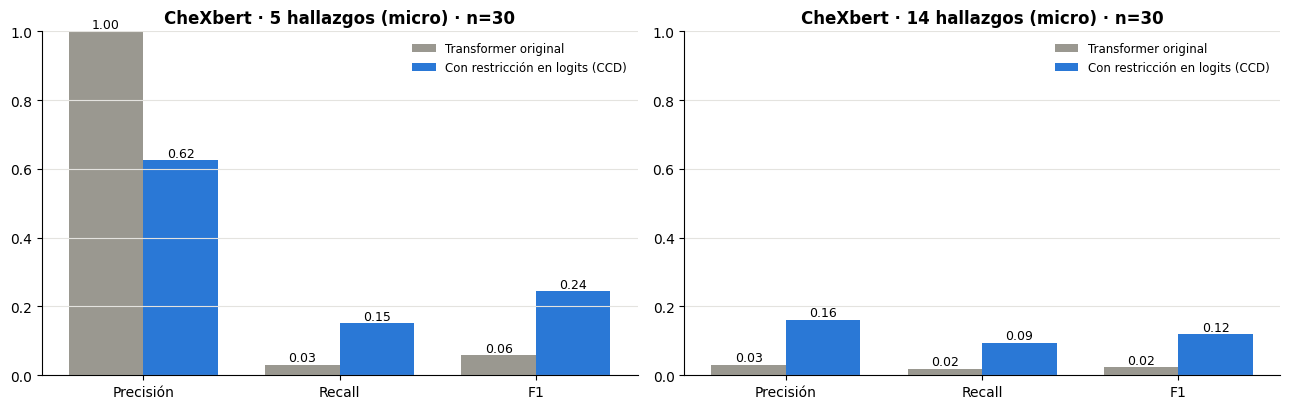

In [14]:
# Vista rápida (primera versión de las gráficas). Las completas, con IC 95 % y AUC, están en las celdas C → H.
# 6) Gráfica antes / después
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    import matplotlib.pyplot as plt
    C_BASE, C_CCD, INK2 = "#9a9890", "#2a78d6", "#52514e"
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                         "axes.titleweight": "bold", "legend.frameon": False})
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, name in zip(axs, ["5 hallazgos", "14 hallazgos"]):
        t = R[(name, "micro")]; x = np.arange(3); w = 0.38
        for off, s, c, lab in [(-w / 2, "base", C_BASE, "Transformer original"), (w / 2, "ccd", C_CCD, "Con restricción en logits (CCD)")]:
            b = ax.bar(x + off, t[s], w, color=c, label=lab)
            for xi, v in zip(x + off, t[s]): ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
        ax.set_xticks(x, ["Precisión", "Recall", "F1"]); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
        ax.set_title(f"CheXbert · {name} (micro) · n={len(keys)}"); ax.legend(loc="upper right", fontsize=8.5)
    plt.tight_layout(); plt.show()

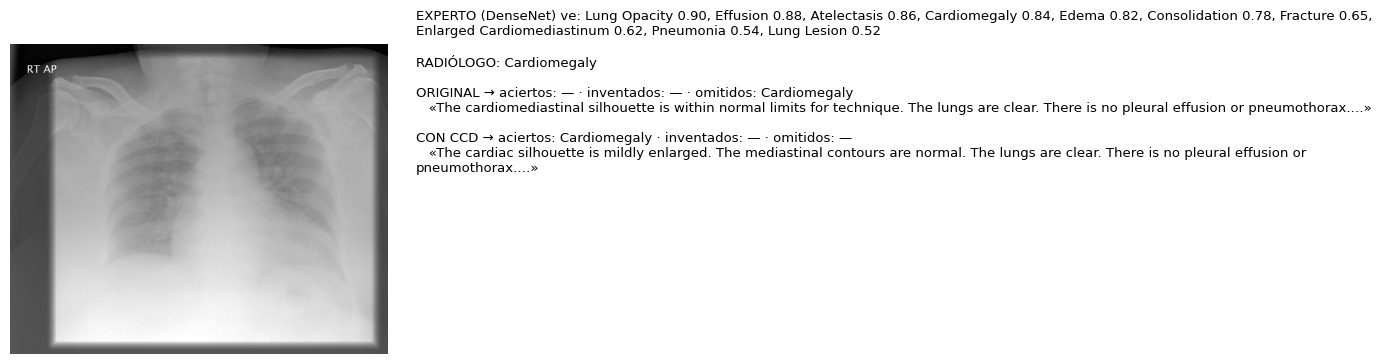

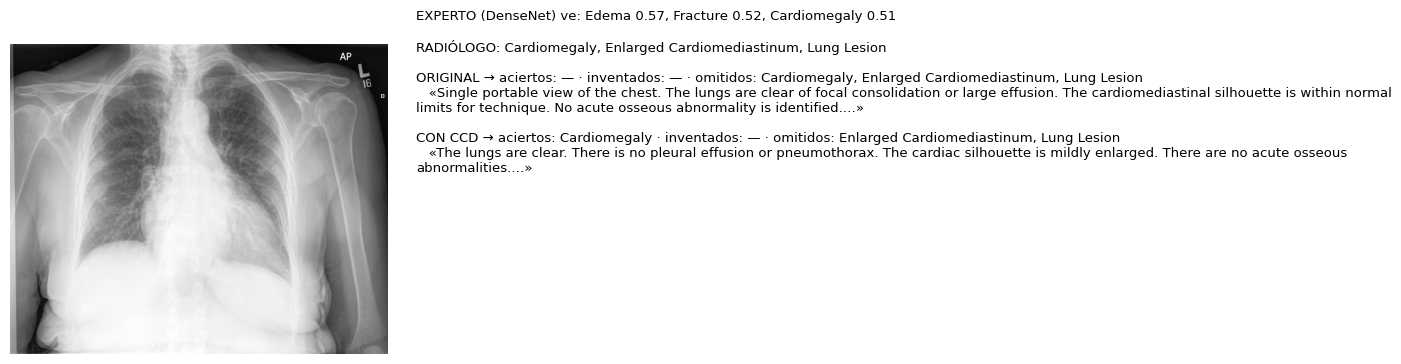

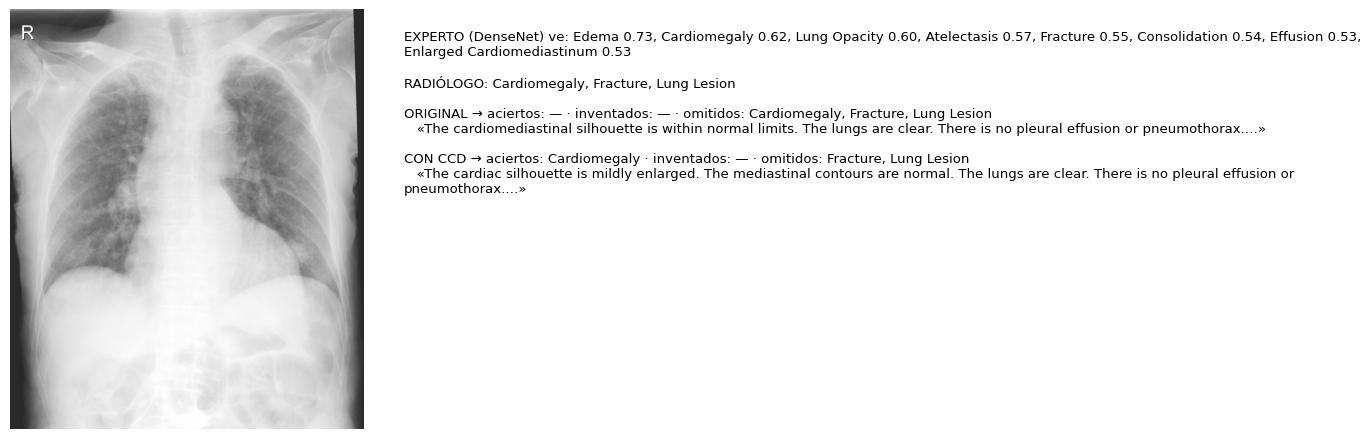

In [15]:
# Vista rápida (primera versión de las gráficas). Las completas, con IC 95 % y AUC, están en las celdas C → H.
# 7) Casos: qué dijo cada versión frente al radiólogo
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    def found(v): return {NAMES[j] for j in range(13) if v[j] == 1}  # sin "No Finding"
    gain = [(len(found(L["ref"][i]) & found(L["ccd"][i])) - len(found(L["ref"][i]) & found(L["base"][i])), i) for i in range(len(keys))]
    for g, i in sorted(gain, reverse=True)[:3]:
        k = keys[i]; r = res[k]; ref, b, c = found(L["ref"][i]), found(L["base"][i]), found(L["ccd"][i])
        exp = sorted(((v, n) for n, v in r["expert"].items() if n not in ("Frontal", "Lateral") and v >= 0.5), reverse=True)
        fig = plt.figure(figsize=(14, 4.2)); ax = fig.add_axes([0, 0, 0.27, 1]); ax.imshow(img_of(sel.loc[int(k)]), cmap="gray"); ax.axis("off")
        txt = (f"EXPERTO (DenseNet) ve: {', '.join(f'{n} {v:.2f}' for v, n in exp) or 'nada ≥0.5'}\n\n"
               f"RADIÓLOGO: {', '.join(sorted(ref)) or 'normal'}\n\n"
               f"ORIGINAL → aciertos: {', '.join(sorted(ref & b)) or '—'} · inventados: {', '.join(sorted(b - ref)) or '—'} · omitidos: {', '.join(sorted(ref - b)) or '—'}\n"
               f"   «{r['base'][:230]}…»\n\n"
               f"CON CCD → aciertos: {', '.join(sorted(ref & c)) or '—'} · inventados: {', '.join(sorted(c - ref)) or '—'} · omitidos: {', '.join(sorted(ref - c)) or '—'}\n"
               f"   «{r['ccd'][:230]}…»")
        fig.text(0.29, 0.95, txt, va="top", fontsize=9.5, wrap=True, family="DejaVu Sans")
        plt.show()

## A. (Opcional) Guardar resultados en Drive
Solo hace falta si vuelves a generar los informes. Los resultados de esta exposición ya están en el repositorio, en [`resultados/ccd_demo/`](../resultados/ccd_demo/).

In [16]:
# Guarda resultados, etiquetas CheXbert e imágenes en Google Drive. Solo hace falta si vuelves a generar los informes.
if not GENERAR:
    print("Omitido (GENERAR = False): se usan los resultados guardados, ver celdas B → H.")
else:
    from google.colab import drive
    drive.mount("/content/drive")
    import os, json, numpy as np
    D = "/content/drive/MyDrive/ccd_demo"; os.makedirs(D + "/img", exist_ok=True)
    for k in keys: img_of(sel.loc[int(k)]).save(f"{D}/img/{k}.png")
    json.dump(res, open(f"{D}/resultados.json", "w"))
    np.savez(f"{D}/etiquetas.npz", ref=L["ref"], base=L["base"], ccd=L["ccd"],
             keys=np.array(keys), names=np.array(NAMES), idx5=np.array(IDX5))
    print("Guardado en Drive:", D, "·", len(keys), "casos")

Mounted at /content/drive
Guardado en Drive: /content/drive/MyDrive/ccd_demo · 30 casos


## B. Cargar los resultados desde este repositorio (sin GPU, sin Drive, sin recalcular)
Desde aquí puedes correr las celdas B → H en cualquier entorno, incluso en un Colab sin GPU.

In [18]:
import io, json, urllib.request
import numpy as np
from PIL import Image
# resultados.json: los 3 textos de cada estudio (radiólogo, original, CCD) + probabilidades del experto
# etiquetas.npz:   etiquetas CheXbert de esos textos (ref / base / ccd), 30 estudios × 14 hallazgos
# img/:            radiografías a 1024 px (solo para mostrarlas)
BASE = "https://raw.githubusercontent.com/santiagovelcasallas/incorporacion-restricciones-aprendizaje-automatico/main/resultados/ccd_demo"
get = lambda ruta: urllib.request.urlopen(f"{BASE}/{ruta}").read()
res = json.loads(get("resultados.json"))
z = np.load(io.BytesIO(get("etiquetas.npz")))
L = {s: z[s] for s in ["ref", "base", "ccd"]}
keys, NAMES, IDX5 = [str(k) for k in z["keys"]], [str(n) for n in z["names"]], [int(i) for i in z["idx5"]]
_cache = {}
def img_k(k):
    if k not in _cache: _cache[k] = Image.open(io.BytesIO(get(f"img/{k}.png")))
    return _cache[k]
print(len(keys), "casos cargados desde GitHub")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
30 casos cargados


## C. Precisión, recall, F1 y AUC con intervalos de confianza (bootstrap pareado, 2000 remuestreos)


5 hallazgos principales  (n=30 estudios con hallazgos)
  Precisión original 1.000 → CCD 0.625   Δ IC95 [-0.667, +0.875]   P(mejora) = 37%
  Recall    original 0.030 → CCD 0.152   Δ IC95 [+0.000, +0.267]   P(mejora) = 95%
  F1        original 0.059 → CCD 0.244   Δ IC95 [-0.011, +0.391]   P(mejora) = 95%
  AUC       original 0.515 → CCD 0.563   Δ IC95 [-0.015, +0.122]   P(mejora) = 93%

14 hallazgos  (n=30 estudios con hallazgos)
  Precisión original 0.031 → CCD 0.161   Δ IC95 [+0.002, +0.269]   P(mejora) = 98%
  Recall    original 0.019 → CCD 0.094   Δ IC95 [+0.000, +0.167]   P(mejora) = 95%
  F1        original 0.024 → CCD 0.119   Δ IC95 [+0.001, +0.205]   P(mejora) = 98%
  AUC       original 0.467 → CCD 0.512   Δ IC95 [+0.003, +0.092]   P(mejora) = 98%


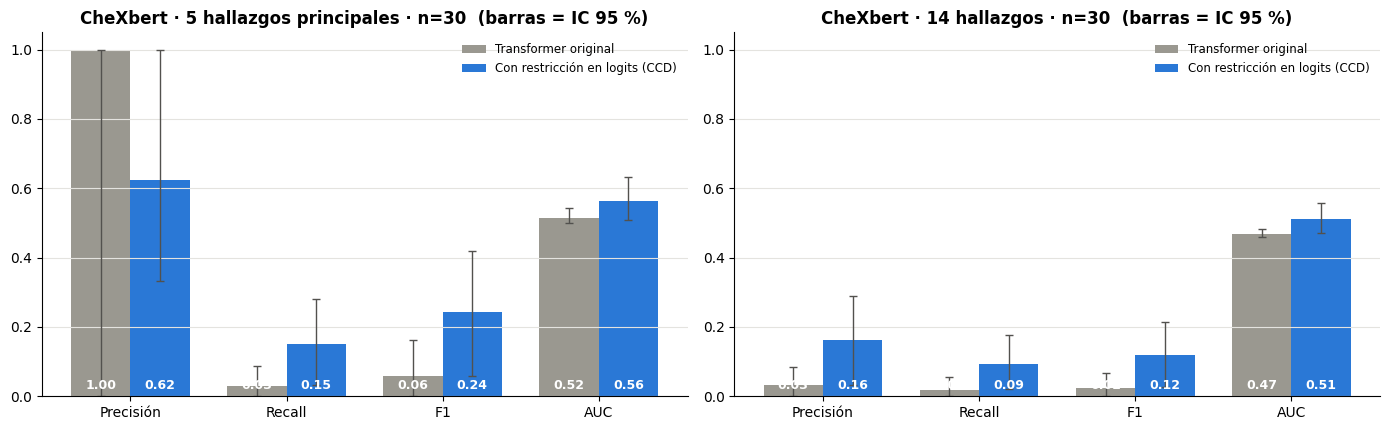

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, roc_curve
C_BASE, C_CCD, C_EXP, INK, INK2 = "#9a9890", "#2a78d6", "#4a3aa7", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.titleweight": "bold", "legend.frameon": False, "font.size": 10})
# Columnas de las etiquetas CheXbert: los 5 hallazgos principales y los 14 completos
COLS5, COLS14 = IDX5, list(range(14))
N5 = [NAMES[j] for j in COLS5]

def metr(yt, yp):
    """precisión, recall, F1 (micro) y AUC. Con predicciones sí/no, AUC = (sensibilidad + especificidad)/2."""
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average="micro", zero_division=0)
    a = roc_auc_score(yt.ravel(), yp.ravel()) if 0 < yt.sum() < yt.size else np.nan
    return np.array([p, r, f, a])

# Bootstrap pareado: se remuestrean los MISMOS pacientes para ambos modelos (2000 veces)
# y se guarda la diferencia CCD − original de cada métrica.
def con_ic(cols, B=2000):
    yt = L["ref"][:, cols]; out = {s: metr(yt, L[s][:, cols]) for s in ["base", "ccd"]}
    rng = np.random.default_rng(0); bb, bc = [], []
    for _ in range(B):
        j = rng.integers(0, len(keys), len(keys))
        bb.append(metr(yt[j], L["base"][j][:, cols])); bc.append(metr(yt[j], L["ccd"][j][:, cols]))
    bb, bc = np.array(bb), np.array(bc)
    out["ci_base"], out["ci_ccd"] = np.nanpercentile(bb, [2.5, 97.5], 0), np.nanpercentile(bc, [2.5, 97.5], 0)
    out["delta"] = bc - bb
    return out

# Tabla impresa abajo. P(mejora) = fracción de remuestreos en que CCD supera al original.
M = {"5 hallazgos principales": con_ic(COLS5), "14 hallazgos": con_ic(COLS14)}
NOM = ["Precisión", "Recall", "F1", "AUC"]
for name, m in M.items():
    print(f"\n{name}  (n={len(keys)} estudios con hallazgos)")
    for i, n in enumerate(NOM):
        d = m["delta"][:, i]; lo, hi = np.nanpercentile(d, [2.5, 97.5])
        print(f"  {n:9s} original {m['base'][i]:.3f} → CCD {m['ccd'][i]:.3f}   Δ IC95 [{lo:+.3f}, {hi:+.3f}]   P(mejora) = {np.nanmean(d > 0):.0%}")

# Barras = valor observado; bigotes = IC 95 % de cada modelo.
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, (name, m) in zip(axs, M.items()):
    x = np.arange(4); w = 0.38
    for off, s, c, lab in [(-w / 2, "base", C_BASE, "Transformer original"), (w / 2, "ccd", C_CCD, "Con restricción en logits (CCD)")]:
        v = m[s]; ci = m["ci_" + s]; err = np.abs(np.vstack([v - ci[0], ci[1] - v]))
        ax.bar(x + off, v, w, color=c, label=lab, yerr=err, ecolor=INK2, capsize=3, error_kw=dict(lw=1))
        for xi, vi in zip(x + off, v): ax.text(xi, 0.02, f"{vi:.2f}", ha="center", color="white", weight="bold", fontsize=9)
    ax.set_xticks(x, NOM); ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False)
    ax.set_title(f"CheXbert · {name} · n={len(keys)}  (barras = IC 95 %)"); ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()

## D. ¿Qué tan probable es que la mejora sea real? (distribución bootstrap de la diferencia)

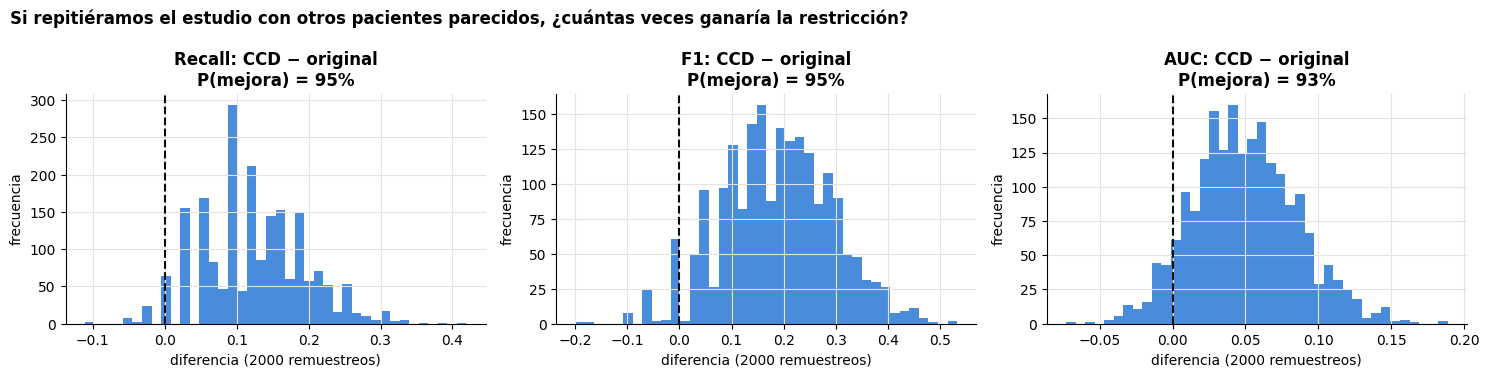

In [20]:
# Histograma de las 2000 diferencias bootstrap (CCD − original) para recall, F1 y AUC (5 hallazgos).
# La línea punteada es 0: la proporción de la masa a su derecha es la probabilidad de que la mejora sea real.
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
m = M["5 hallazgos principales"]
for ax, i in zip(axs, [1, 2, 3]):
    d = m["delta"][:, i]; d = d[~np.isnan(d)]
    ax.hist(d, bins=40, color=C_CCD, alpha=0.85, ec="white", lw=0.5)
    ax.axvline(0, color=INK, lw=1.5, ls="--")
    ax.set(title=f"{NOM[i]}: CCD − original\nP(mejora) = {np.mean(d > 0):.0%}", xlabel="diferencia (2000 remuestreos)", ylabel="frecuencia")
fig.suptitle("Si repitiéramos el estudio con otros pacientes parecidos, ¿cuántas veces ganaría la restricción?", x=0.01, ha="left", weight="bold")
plt.tight_layout(); plt.show()

## E. Matrices de confusión y recall por hallazgo

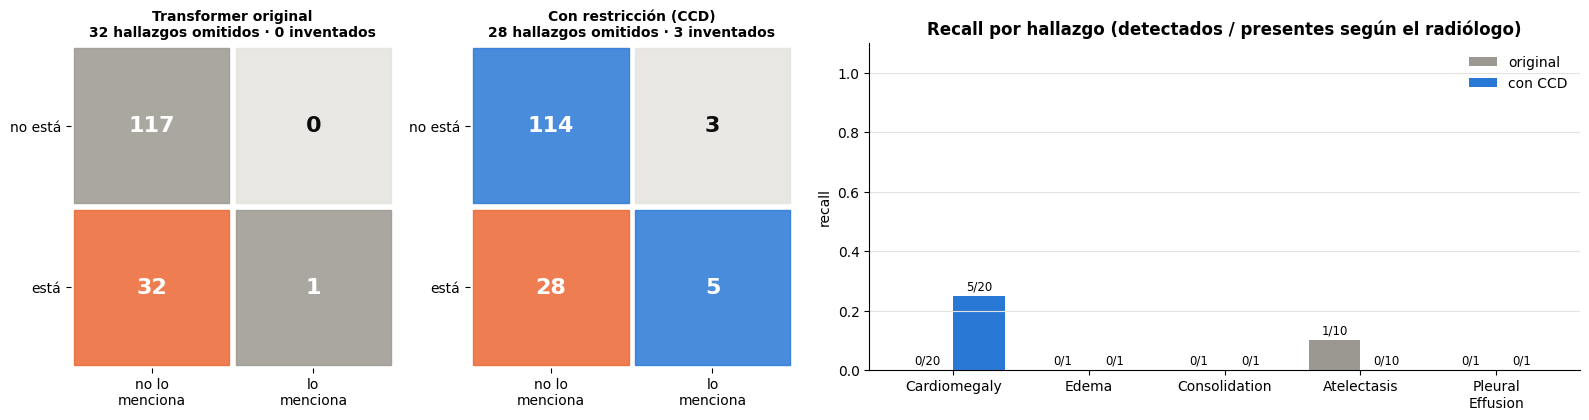

In [21]:
# Matrices de confusión sobre 5 hallazgos × 30 estudios (150 pares). Naranja = hallazgo que el radiólogo
# reportó y el informe omitió (falso negativo): justo lo que la restricción intenta reducir.
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1, 2.2]})
yt = L["ref"][:, COLS5].ravel()
for ax, s, c, ttl in [(axs[0], "base", C_BASE, "Transformer original"), (axs[1], "ccd", C_CCD, "Con restricción (CCD)")]:
    yp = L[s][:, COLS5].ravel()
    Mx = np.array([[((yt == 0) & (yp == 0)).sum(), ((yt == 0) & (yp == 1)).sum()], [((yt == 1) & (yp == 0)).sum(), ((yt == 1) & (yp == 1)).sum()]])
    ax.imshow(np.zeros((2, 2)), cmap="Greys", vmin=0, vmax=1); ax.grid(False)
    for (r, cc), v in np.ndenumerate(Mx):
        col = "#eb6834" if (r == 1 and cc == 0) else (c if r == cc else "#e4e3df")
        ax.add_patch(plt.Rectangle((cc - .48, r - .48), .96, .96, color=col, alpha=.85))
        ax.text(cc, r, str(v), ha="center", va="center", fontsize=16, weight="bold", color="white" if r == cc or (r == 1 and cc == 0) else INK)
    ax.set_xticks([0, 1], ["no lo\nmenciona", "lo\nmenciona"]); ax.set_yticks([0, 1], ["no está", "está"])
    ax.set_title(f"{ttl}\n{Mx[1,0]} hallazgos omitidos · {Mx[0,1]} inventados", fontsize=10)
    for sp in ax.spines.values(): sp.set_visible(False)
# Recall por hallazgo: de los casos donde el radiólogo lo reportó, cuántos menciona cada informe
pos = L["ref"][:, COLS5].sum(0); x = np.arange(5); w = 0.38
for off, s, c, lab in [(-w / 2, "base", C_BASE, "original"), (w / 2, "ccd", C_CCD, "con CCD")]:
    det = (L[s][:, COLS5] & L["ref"][:, COLS5]).sum(0)
    axs[2].bar(x + off, det / np.maximum(pos, 1), w, color=c, label=lab)
    for xi, d_, p_ in zip(x + off, det, pos): axs[2].text(xi, d_ / max(p_, 1) + 0.02, f"{d_}/{p_}", ha="center", fontsize=8.5)
axs[2].set_xticks(x, [n.replace("Pleural ", "Pleural\n") for n in N5]); axs[2].set_ylim(0, 1.1)
axs[2].set(title="Recall por hallazgo (detectados / presentes según el radiólogo)", ylabel="recall"); axs[2].legend(); axs[2].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## F. Curvas ROC: experto (referencia) y Transformer antes y después de la restricción

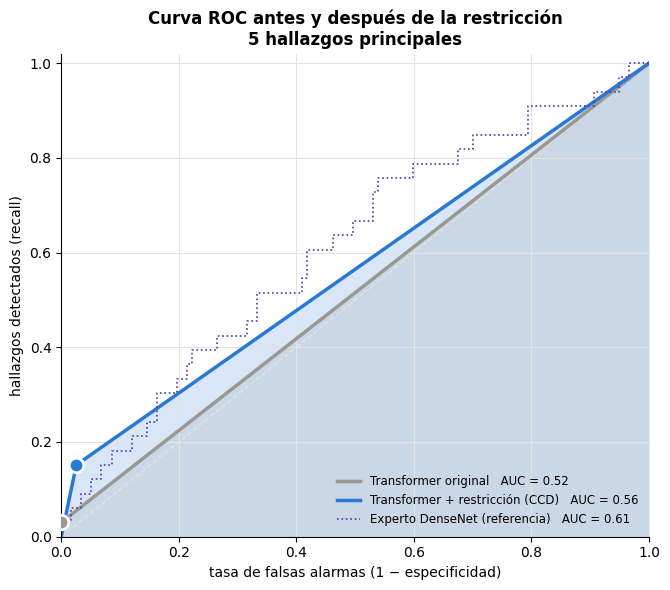

In [25]:
# El Transformer solo dice sí/no por hallazgo → su curva ROC es (0,0) → su punto → (1,1) y su AUC = (sens + espec)/2.
# El experto da probabilidades continuas → curva escalonada (referencia). XRV traduce nombres (torchxrayvision usa 'Effusion').
XRV = {"Cardiomegaly": "Cardiomegaly", "Edema": "Edema", "Consolidation": "Consolidation",
       "Atelectasis": "Atelectasis", "Pleural Effusion": "Effusion"}
yt = L["ref"][:, COLS5].ravel()
fig, ax = plt.subplots(figsize=(6.8, 6))
ax.plot([0, 1], [0, 1], color="#e4e3df", ls="--", lw=1)
# curva ROC de cada versión del Transformer: (0,0) → su punto (falsas alarmas, recall) → (1,1)
for s, c, lab in [("base", C_BASE, "Transformer original"), ("ccd", C_CCD, "Transformer + restricción (CCD)")]:
    yp = L[s][:, COLS5].ravel(); tp = yp[yt == 1].mean(); fp = yp[yt == 0].mean()
    fx, fy = [0, fp, 1], [0, tp, 1]
    ax.fill_between(fx, fy, color=c, alpha=0.18, lw=0)
    ax.plot(fx, fy, color=c, lw=2.5, label=f"{lab}   AUC = {roc_auc_score(yt, yp):.2f}")
    ax.scatter(fp, tp, s=110, color=c, ec="white", lw=2, zorder=3)
# referencia: el experto que guía a CCD (da probabilidades continuas)
ys, ss = [], []
for i, k in enumerate(keys):
    for j, n in zip(COLS5, N5):
        ys.append(L["ref"][i, j]); ss.append(res[k]["expert"].get(XRV[n], np.nan))
ys, ss = np.array(ys), np.array(ss); ok = ~np.isnan(ss)
fpr, tpr, _ = roc_curve(ys[ok], ss[ok])
ax.plot(fpr, tpr, color=C_EXP, lw=1.2, ls=":", label=f"Experto DenseNet (referencia)   AUC = {roc_auc_score(ys[ok], ss[ok]):.2f}")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="tasa de falsas alarmas (1 − especificidad)", ylabel="hallazgos detectados (recall)",
       title="Curva ROC antes y después de la restricción\n5 hallazgos principales")
ax.legend(loc="lower right", fontsize=8.5); plt.tight_layout(); plt.show()

## G. Caso por caso: ¿a cuántos pacientes ayudó la restricción?

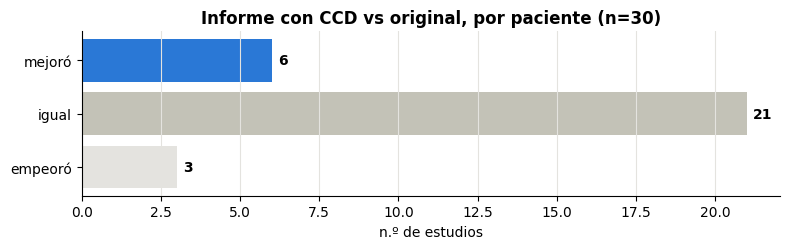

In [23]:
def score(i, s):  # aciertos − inventados en los 13 hallazgos (sin "No Finding")
    r, h = L["ref"][i, :13], L[s][i, :13]; return int((r & h).sum()) - int((h & (1 - r)).sum())
# Por paciente: puntaje con CCD − puntaje original → > 0 mejoró, 0 igual, < 0 empeoró
net = np.array([score(i, "ccd") - score(i, "base") for i in range(len(keys))])
ayudo, igual, empeoro = (net > 0).sum(), (net == 0).sum(), (net < 0).sum()
fig, ax = plt.subplots(figsize=(8, 2.6))
b = ax.barh(["empeoró", "igual", "mejoró"], [empeoro, igual, ayudo], color=["#e4e3df", "#c3c2b7", C_CCD])
for r, v in zip(b, [empeoro, igual, ayudo]): ax.text(v + 0.2, r.get_y() + r.get_height() / 2, str(v), va="center", weight="bold")
ax.set(title=f"Informe con CCD vs original, por paciente (n={len(keys)})", xlabel="n.º de estudios"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## H. Galería: casos donde la restricción sí ayudó

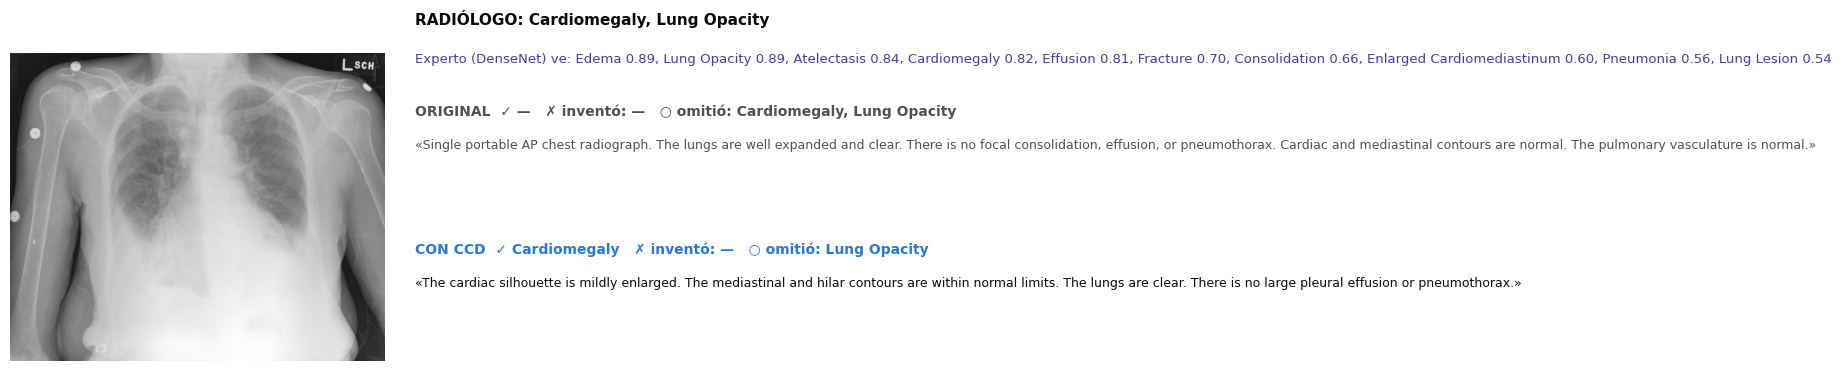

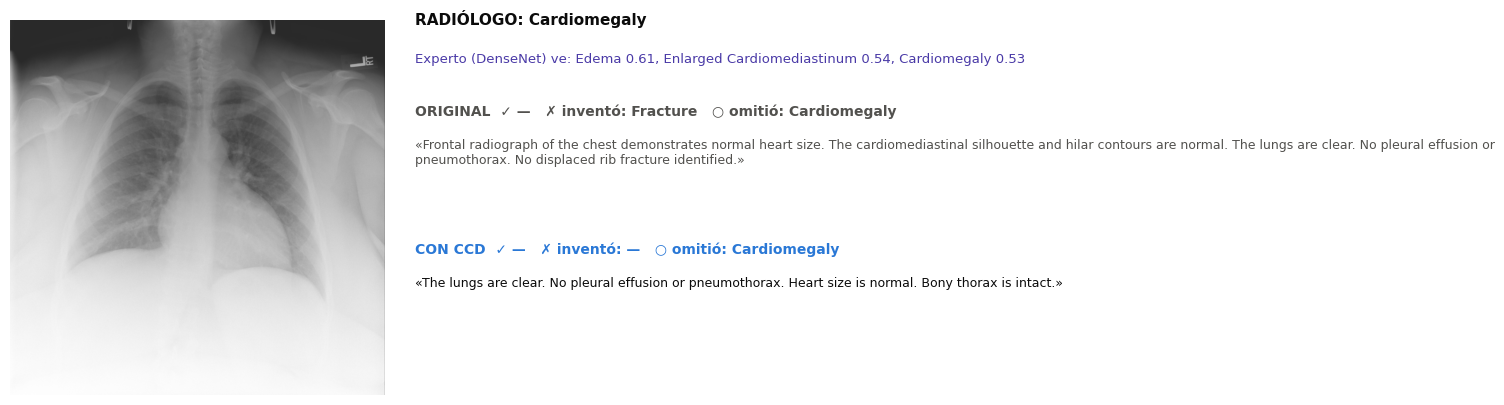

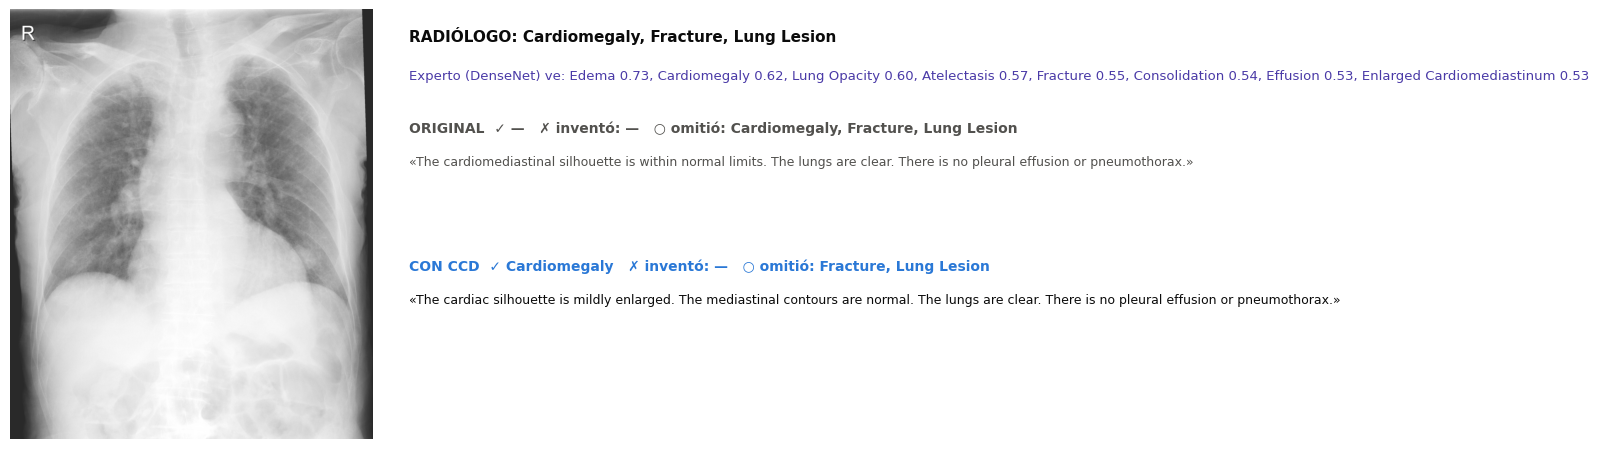

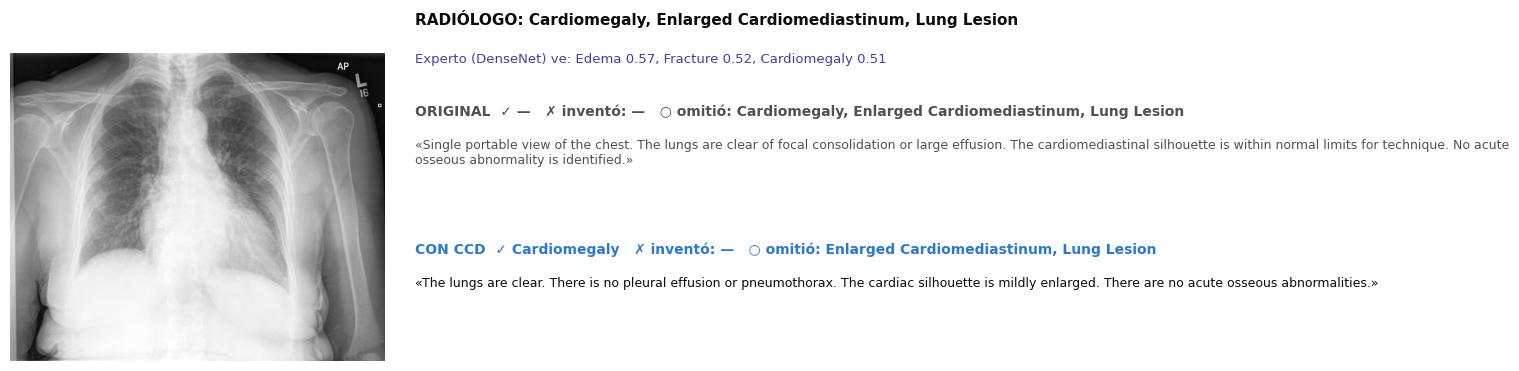

Balance honesto: mejoró 6, igual 21, empeoró 3 de 30 estudios.


In [24]:
# Los 4 estudios donde CCD más mejoró (ver celda G).
# ✓ = hallazgo del radiólogo que el informe menciona · ✗ = mencionado sin estar · ○ = omitido.
def found(v): return {NAMES[j] for j in range(13) if v[j] == 1}
TOP = [i for i in np.argsort(-net) if net[i] > 0][:4]
for i in TOP:
    k = keys[i]; r = res[k]; ref, b_, c_ = found(L["ref"][i]), found(L["base"][i]), found(L["ccd"][i])
    exp = sorted(((v, n) for n, v in r["expert"].items() if n not in ("Frontal", "Lateral") and v >= 0.5), reverse=True)
    fig = plt.figure(figsize=(15, 4.3)); ax = fig.add_axes([0, 0, 0.25, 1]); ax.imshow(img_k(k), cmap="gray"); ax.axis("off")
    j = lambda S: ", ".join(sorted(S)) or "—"
    fig.text(0.27, 0.96, f"RADIÓLOGO: {j(ref)}", va="top", fontsize=11, weight="bold", color=INK)
    fig.text(0.27, 0.86, f"Experto (DenseNet) ve: {', '.join(f'{n} {v:.2f}' for v, n in exp) or 'nada ≥0.5'}", va="top", fontsize=9.5, color=C_EXP)
    fig.text(0.27, 0.74, f"ORIGINAL  ✓ {j(ref & b_)}   ✗ inventó: {j(b_ - ref)}   ○ omitió: {j(ref - b_)}", va="top", fontsize=10, color=INK2, weight="bold")
    fig.text(0.27, 0.66, "«" + r["base"][:300] + "»", va="top", fontsize=9, color=INK2, wrap=True)
    fig.text(0.27, 0.42, f"CON CCD  ✓ {j(ref & c_)}   ✗ inventó: {j(c_ - ref)}   ○ omitió: {j(ref - c_)}", va="top", fontsize=10, color=C_CCD, weight="bold")
    fig.text(0.27, 0.34, "«" + r["ccd"][:300] + "»", va="top", fontsize=9, color=INK, wrap=True)
    plt.show()
print(f"Balance honesto: mejoró {ayudo}, igual {igual}, empeoró {empeoro} de {len(keys)} estudios.")